In [19]:
# Baris berikut mendefinisikan string koneksi ke database Neo4J
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "gsd_2026")

In [20]:
# Baris perintah berikut melakukan pembuatan sebuah Node berikut dengan relationship-nya.
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

In [21]:
# Untuk mencetak dan menjalankan keseluruhan
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


1. Apa nama database yang digunakan pada tutorial ini?
- neo4j
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!
- :use nama_database	(untuk memilih database aktif di Neo4j Browser)
3. Apa jenis graf pertemanan yang telah dibuat di sini?
- Graf pertemanan yang dibuat merupakan graf berarah (directed graph) karena relasi KNOWS memiliki arah dari satu node orang menuju node orang lainnya.

In [31]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("neo4j://localhost:7687", auth=("neo4j", "gsd_2026"))
session = driver.session(database="neo4j")

In [23]:
import argparse

def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="gsd_2026",
        help="Password Neo4J (default: gsd_2026)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    
    return parser.parse_args(args=[])

In [24]:
import os
import sys

args = parse_arguments()

# Diawali oleh pemeriksaan keberadaan berkas events.csv
csv_file_path = os.path.join(args.source, r"D:\Semester 7\Graf Sains Data\Tugas\UTS\ecommerce-dataset\events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

In [25]:
# Dilanjutkan dengan pembuatan koneksi
try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

In [26]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

    print("Constraint Visitor dan Item berhasil dibuat.")

In [ ]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        MERGE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """

    tx.run(cypher_query, batch=batch)


In [28]:
import math
import pandas as pd
from tqdm import tqdm

batch_size = 10000

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")

    with open(csv_file_path, encoding="utf-8") as f:
        total_rows = sum(1 for _ in f) - 1

    total_chunks = math.ceil(total_rows / batch_size)

    print(f"Total baris data: {total_rows:,}")
    print(f"Ukuran batch: {batch_size:,}")
    print(f"Total batch: {total_chunks}")
    print("Memulai proses impor data ke Neo4j...")

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size,
        encoding="utf-8"
    )

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")


Constraint Visitor dan Item berhasil dibuat.
Membaca file data dari: D:\Semester 7\Graf Sains Data\Tugas\UTS\ecommerce-dataset\events.csv
Total baris data: 2,756,101
Ukuran batch: 10,000
Total batch: 276
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [10:20<00:00,  2.25s/it]

Proses impor berhasil.


## **2.1 Wrangling dan EDA**

### Menentukan periode waktu sebagai filter dari data interaksi (Nomor 1 dan 2)

In [29]:
import pandas as pd

# Periode P1
p1_start = "2015-05-03 00:00:00"
p1_end   = "2015-05-24 00:00:00"

# Periode P2
p2_start = "2015-08-25 00:00:00"
p2_end   = "2015-09-15 00:00:00"

# Baca data interaksi
df = pd.read_csv(csv_file_path)

# Konversi Unix timestamp milidetik menjadi datetime
df["tanggal"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# Filter P1
p1 = df[
    (df["tanggal"] >= pd.Timestamp(p1_start)) &
    (df["tanggal"] < pd.Timestamp(p1_end))
].copy()

# Filter P2
p2 = df[
    (df["tanggal"] >= pd.Timestamp(p2_start)) &
    (df["tanggal"] < pd.Timestamp(p2_end))
].copy()

# Simpan langsung sebagai file CSV tanpa membuat folder
p1.drop(columns=["tanggal"]).to_csv(
    "retailrocket_P1.csv",
    index=False
)

p2.drop(columns=["tanggal"]).to_csv(
    "retailrocket_P2.csv",
    index=False
)

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))
print("Total data terfilter:", len(p1) + len(p2))
print("File berhasil disimpan:")
print(" - retailrocket_P1.csv")
print(" - retailrocket_P2.csv")


Jumlah data P1: 431585
Jumlah data P2: 387829
Total data terfilter: 819414
File berhasil disimpan:
 - retailrocket_P1.csv
 - retailrocket_P2.csv


### Query untuk komposisi subgraph (Nomor 3)

In [32]:
with driver.session(database="neo4j") as session:

    # Menghitung jumlah setiap jenis simpul
    result_node = session.run("""
        MATCH (n)
        RETURN labels(n) AS jenis_simpul,
               count(n) AS jumlah
    """)

    df_node = pd.DataFrame(
        [record.data() for record in result_node]
    )

    # Menghitung jumlah setiap jenis relasi
    result_relasi = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi,
               count(r) AS jumlah
        ORDER BY jumlah DESC
    """)

    df_relasi = pd.DataFrame(
        [record.data() for record in result_relasi]
    )

print("Komposisi Simpul:")
display(df_node)

print("Komposisi Relasi:")
display(df_relasi)


Komposisi Simpul:


,jenis_simpul,jumlah
0,[Person],4
1,[Visitor],1407580
2,[Item],235061


Komposisi Relasi:


,jenis_relasi,jumlah
0,VIEWED,2664218
1,ADDED_TO_CART,68966
2,BOUGHT,22457
3,KNOWS,3


Penjelasan Cypher yang digunakan
- MATCH (n) mengambil semua node dalam database yang dipilih.
- labels(n) mengambil label setiap node, misalnya Visitor dan Item.
- count(n) menghitung jumlah node untuk setiap kelompok label yang dikembalikan.
- MATCH ()-[r]->() mengambil semua relasi yang memiliki node asal dan tujuan.
- type(r) mengambil jenis relasi, misalnya VIEWED, ADDED_TO_CART, dan BOUGHT.
- count(r) menghitung jumlah relasi untuk setiap jenis.
- ORDER BY jumlah DESC mengurutkan hasil dari jumlah relasi terbanyak ke paling sedikit.

Penjelasan komposisi simpul
- Visitor: 1.407.580 simpul. Merupakan simpul yang merepresentasikan pengunjung dalam dataset. Jumlah ini menunjukkan banyaknya pengunjung unik yang tersimpan sebagai simpul di graf.
- Item: 235.061 simpul. Merepresentasikan item yang terlibat dalam aktivitas pengunjung, seperti dilihat, dimasukkan ke keranjang, atau dibeli.
- Person: 4 simpul. Terdapat empat simpul dengan label Person di dalam database. 

Penjelasan komposisi relasi
- VIEWED: 2.664.218 relasi. Menunjukkan hubungan aktivitas pengunjung melihat item dan menjadi jenis relasi terbanyak.
- ADDED_TO_CART: 68.966 relasi. Menunjukkan aktivitas pengunjung menambahkan item ke keranjang belanja.
- BOUGHT: 22.457 relasi. Menunjukkan aktivitas pembelian item oleh pengunjung.
- KNOWS: 3 relasi. Merupakan relasi tambahan yang jumlahnya sangat sedikit dibandingkan relasi aktivitas belanja lainnya.

### Membentuk matriks VSM User–Item (Nomor 4)

In [33]:
import numpy as np
from scipy.sparse import coo_matrix

# 1. Membaca data periode P1
df_p1 = pd.read_csv("retailrocket_P1.csv")

# Memastikan kolom tersedia
print("Kolom:", df_p1.columns.tolist())
print("Jumlah baris data P1:", len(df_p1))

# 2. Membuat indeks unik Visitor dan Item
visitor_codes, visitor_ids = pd.factorize(df_p1["visitorid"])
item_codes, item_ids = pd.factorize(df_p1["itemid"])

n_users = len(visitor_ids)
n_items = len(item_ids)

# 3. Membentuk matriks User-Item
# Nilai 1 menunjukkan ada interaksi Visitor dengan Item
VSM = coo_matrix(
    (
        np.ones(len(df_p1), dtype=np.int8),
        (visitor_codes, item_codes)
    ),
    shape=(n_users, n_items)
).tocsr()

# Mengubah interaksi berulang menjadi nilai biner 1
VSM.sum_duplicates()
VSM.data[:] = 1
VSM.eliminate_zeros()

print("\nKarakteristik VSM User-Item")
print("Jumlah Visitor:", n_users)
print("Jumlah Item:", n_items)
print("Shape matriks:", VSM.shape)
print("Jumlah interaksi unik Visitor-Item:", VSM.nnz)
print("Jumlah elemen matriks:", VSM.shape[0] * VSM.shape[1])
print("Sparsity: {:.4f}%".format(
    100 * (1 - VSM.nnz / (VSM.shape[0] * VSM.shape[1]))
))

Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Jumlah baris data P1: 431585

Karakteristik VSM User-Item
Jumlah Visitor: 225151
Jumlah Item: 97328
Shape matriks: (225151, 97328)
Jumlah interaksi unik Visitor-Item: 336302
Jumlah elemen matriks: 21913496528
Sparsity: 99.9985%


### Visualisasi proyeksi User menggunakan NetworkX

Jumlah simpul graf: 30
Jumlah relasi graf: 345


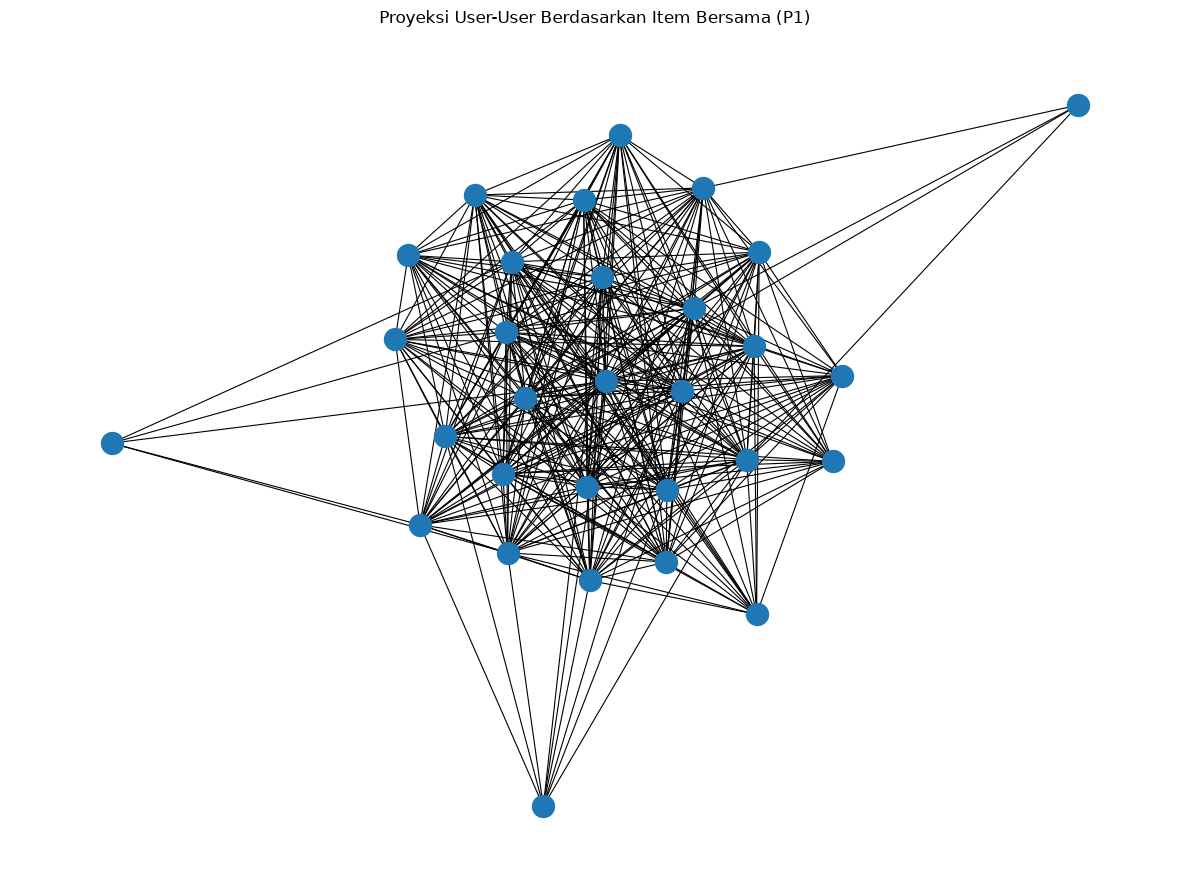

In [34]:
import networkx as nx
import matplotlib.pyplot as plt

# Jumlah item unik yang diinteraksikan setiap Visitor
items_per_visitor = np.asarray(VSM.sum(axis=1)).ravel()

# 1. Memilih 30 Visitor paling aktif
top_n = min(30, n_users)
top_indices = np.argsort(items_per_visitor)[-top_n:][::-1]

VSM_top = VSM[top_indices]

# 2. Menghitung jumlah item yang sama antar-Visitor
shared_items = (VSM_top @ VSM_top.T).toarray()

# 3. Membentuk graf User-User
G_user = nx.Graph()

for i, idx in enumerate(top_indices):
    G_user.add_node(str(visitor_ids[idx]),
                    jumlah_item=int(items_per_visitor[idx]))

for i in range(top_n):
    for j in range(i + 1, top_n):
        # Minimal 2 item yang sama agar terbentuk relasi
        if shared_items[i, j] >= 2:
            G_user.add_edge(
                str(visitor_ids[top_indices[i]]),
                str(visitor_ids[top_indices[j]]),
                shared_items=int(shared_items[i, j])
            )

print("Jumlah simpul graf:", G_user.number_of_nodes())
print("Jumlah relasi graf:", G_user.number_of_edges())

# 4. Visualisasi NetworkX
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_user, seed=42)

nx.draw_networkx(
    G_user,
    pos,
    with_labels=False,
    node_size=250,
    width=0.8
)

plt.title("Proyeksi User-User Berdasarkan Item Bersama (P1)")
plt.axis("off")
plt.tight_layout()
plt.show()


Cara membaca plot:
- Simpul (node): masing-masing mewakili satu Visitor.
- Sisi (edge): menunjukkan dua Visitor memiliki minimal dua item yang sama.
- Kelompok simpul yang saling terhubung: dapat mengindikasikan pola interaksi item yang serupa.
- Simpul tanpa sisi: tidak memiliki pasangan dengan jumlah item bersama yang memenuhi ambang dua pada kelompok 30 Visitor yang dipilih.

### Vector Space Modelling pada Simpul User

Vector Space Modelling (VSM) dilakukan dengan merepresentasikan simpul Visitor sebagai baris dan simpul Item sebagai kolom dalam matriks User–Item. Penelitian ini menggunakan data periode P1 sebagai data pelatihan. Setiap elemen matriks bernilai 1 apabila pengunjung pernah berinteraksi dengan item terkait, dan 0 apabila tidak terdapat interaksi yang tercatat.

Berdasarkan hasil pengolahan, matriks VSM memiliki shape sebesar (225151, 97328), dengan dua dimensi yang merepresentasikan pengunjung dan item. Matriks tersebut bersifat sparse karena tidak semua pengunjung berinteraksi dengan seluruh item yang tersedia. Karakteristik ini membuat representasi sparse matrix lebih efisien daripada menyimpan seluruh elemen matriks secara penuh.

Selanjutnya, dilakukan visualisasi menggunakan NetworkX melalui proyeksi User–User. Dua pengunjung dihubungkan apabila memiliki minimal dua item yang sama. Visualisasi ini digunakan untuk mengamati kemiripan pola interaksi antarpengunjung.

### Membentuk matriks VSM Item–User (Nomor 5)

In [35]:
# 1. Membaca data periode P1
df_p1 = pd.read_csv("retailrocket_P1.csv")

# 2. Membuat indeks Visitor dan Item
visitor_codes, visitor_ids = pd.factorize(df_p1["visitorid"])
item_codes, item_ids = pd.factorize(df_p1["itemid"])

n_users = len(visitor_ids)
n_items = len(item_ids)

# 3. Membentuk matriks Item-User
VSM_item = coo_matrix(
    (
        np.ones(len(df_p1), dtype=np.int8),
        (item_codes, visitor_codes)
    ),
    shape=(n_items, n_users)
).tocsr()

# Mengubah interaksi berulang menjadi nilai biner 1
VSM_item.sum_duplicates()
VSM_item.data[:] = 1
VSM_item.eliminate_zeros()

# 4. Menampilkan karakteristik matriks
print("Karakteristik VSM Item-User")
print("Jumlah Item:", n_items)
print("Jumlah Visitor:", n_users)
print("Shape matriks:", VSM_item.shape)
print("Jumlah interaksi unik Item-Visitor:", VSM_item.nnz)
print("Jumlah elemen matriks:", VSM_item.shape[0] * VSM_item.shape[1])
print("Sparsity: {:.4f}%".format(
    100 * (1 - VSM_item.nnz /
           (VSM_item.shape[0] * VSM_item.shape[1]))
))


Karakteristik VSM Item-User
Jumlah Item: 97328
Jumlah Visitor: 225151
Shape matriks: (97328, 225151)
Jumlah interaksi unik Item-Visitor: 336302
Jumlah elemen matriks: 21913496528
Sparsity: 99.9985%


### Visualisasi proyeksi Item menggunakan NetworkX

Jumlah simpul graf: 30
Jumlah relasi graf: 76


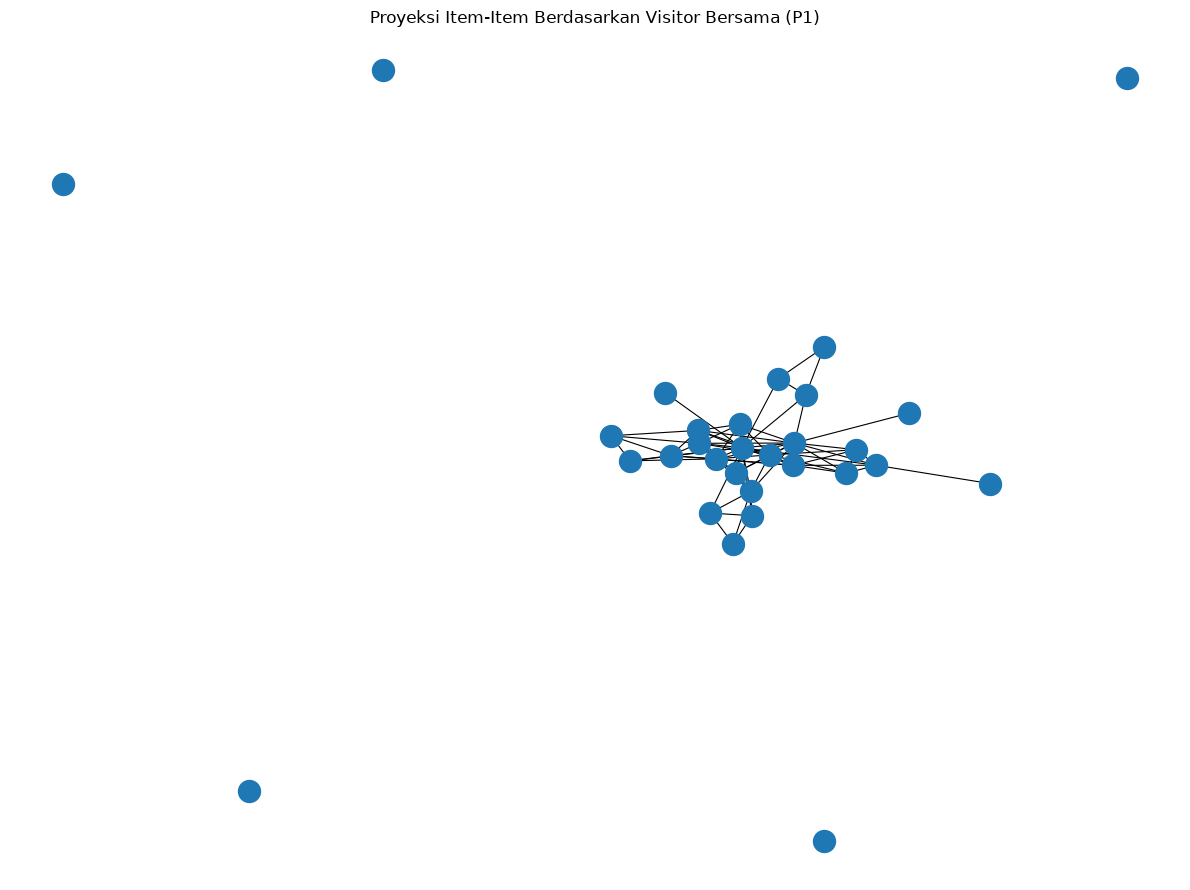

In [36]:
# Jumlah Visitor unik untuk setiap Item
visitors_per_item = np.asarray(
    VSM_item.sum(axis=1)
).ravel()

# 1. Memilih 30 Item dengan Visitor terbanyak
top_n = min(30, n_items)
top_indices = np.argsort(visitors_per_item)[-top_n:][::-1]

VSM_item_top = VSM_item[top_indices]

# 2. Menghitung jumlah Visitor yang sama antar-Item
shared_visitors = (
    VSM_item_top @ VSM_item_top.T
).toarray()

# 3. Membentuk graf Item-Item
G_item = nx.Graph()

for i, idx in enumerate(top_indices):
    G_item.add_node(
        str(item_ids[idx]),
        jumlah_visitor=int(visitors_per_item[idx])
    )

for i in range(top_n):
    for j in range(i + 1, top_n):
        if shared_visitors[i, j] >= 2:
            G_item.add_edge(
                str(item_ids[top_indices[i]]),
                str(item_ids[top_indices[j]]),
                shared_visitors=int(shared_visitors[i, j])
            )

print("Jumlah simpul graf:", G_item.number_of_nodes())
print("Jumlah relasi graf:", G_item.number_of_edges())

# 4. Visualisasi graf
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos,
    with_labels=False,
    node_size=250,
    width=0.8
)

plt.title("Proyeksi Item-Item Berdasarkan Visitor Bersama (P1)")
plt.axis("off")
plt.tight_layout()
plt.show()

Cara membaca plot:
- Node: merepresentasikan satu item.
- Edge: menunjukkan dua item memiliki minimal dua Visitor yang sama.
- Kelompok item yang saling terhubung: mengindikasikan adanya kesamaan pengunjung yang berinteraksi dengan item-item tersebut.
- Jumlah edge: menunjukkan banyaknya pasangan item yang memenuhi ambang minimal dua Visitor bersama.

### Vector Space Modelling pada Simpul Item

Vector Space Modelling (VSM) terhadap simpul Item dilakukan dengan merepresentasikan setiap item sebagai baris dan setiap Visitor sebagai kolom dalam matriks Item–User. Penelitian ini menggunakan data periode P1. Setiap elemen matriks bernilai 1 apabila terdapat interaksi antara pengunjung dan item terkait, sedangkan nilai 0 menunjukkan tidak adanya interaksi yang tercatat.

Berdasarkan hasil pengolahan, matriks VSM Item–User memiliki shape sebesar (97328, 225151). Matriks tersebut memiliki dua dimensi yang menggambarkan item dan pengunjung. Representasi ini memungkinkan setiap item dianalisis berdasarkan pola pengunjung yang berinteraksi dengannya. Karena tidak semua pengunjung berinteraksi dengan seluruh item, matriks cenderung bersifat sparse sehingga representasi sparse matrix lebih efisien digunakan.

Visualisasi menggunakan NetworkX dilakukan melalui proyeksi Item–Item. Dua item dihubungkan apabila memiliki minimal dua pengunjung yang sama. Proyeksi ini membantu mengidentifikasi kemiripan pola interaksi ant item berdasarkan pengunjungnya.

### Ukur efisiensi komputasi

In [37]:
import time

def ukur_proyeksi(matriks, nama, ambang=2):
    # Mengukur waktu pembentukan matriks kemiripan
    mulai = time.perf_counter()
    kemiripan = (matriks @ matriks.T).toarray()
    waktu_matriks = time.perf_counter() - mulai

    # Mengukur waktu pembentukan graf
    mulai = time.perf_counter()
    G = nx.Graph()
    G.add_nodes_from(range(matriks.shape[0]))

    for i in range(matriks.shape[0]):
        for j in range(i + 1, matriks.shape[0]):
            if kemiripan[i, j] >= ambang:
                G.add_edge(i, j, weight=int(kemiripan[i, j]))

    waktu_graf = time.perf_counter() - mulai

    return {
        "Proyeksi": nama,
        "Jumlah Simpul": G.number_of_nodes(),
        "Jumlah Relasi": G.number_of_edges(),
        "Density": nx.density(G),
        "Waktu Matriks (detik)": waktu_matriks,
        "Waktu Graf (detik)": waktu_graf,
        "Total Waktu (detik)": waktu_matriks + waktu_graf
    }

hasil_efisiensi = pd.DataFrame([
    ukur_proyeksi(VSM_top, "User-User"),
    ukur_proyeksi(VSM_item_top, "Item-Item")
])

display(hasil_efisiensi.round(4))


,Proyeksi,Jumlah Simpul,Jumlah Relasi,Density,Waktu Matriks (detik),Waktu Graf (detik),Total Waktu (detik)
0,User-User,30,345,0.7931,0.0030,0.0028,0.0057
1,Item-Item,30,76,0.1747,0.0023,0.0012,0.0035


### Ukur efektivitas proyeksi

In [38]:
def ukur_efektivitas(matriks, nama, ambang=2):
    kemiripan = (matriks @ matriks.T).toarray()
    nilai = kemiripan[np.triu_indices(matriks.shape[0], k=1)]

    pasangan_terhubung = nilai[nilai >= ambang]

    return {
        "Proyeksi": nama,
        "Jumlah Pasangan Terhubung": len(pasangan_terhubung),
        "Rata-rata Kesamaan": (
            pasangan_terhubung.mean()
            if len(pasangan_terhubung) > 0 else 0
        ),
        "Kesamaan Maksimum": (
            pasangan_terhubung.max()
            if len(pasangan_terhubung) > 0 else 0
        )
    }

hasil_efektivitas = pd.DataFrame([
    ukur_efektivitas(VSM_top, "User-User"),
    ukur_efektivitas(VSM_item_top, "Item-Item")
])

display(hasil_efektivitas.round(4))


,Proyeksi,Jumlah Pasangan Terhubung,Rata-rata Kesamaan,Kesamaan Maksimum
0,User-User,345,14.2000,80
1,Item-Item,76,6.9211,37


### Perbandingan Efektivitas dan Efisiensi Proyeksi (Nomor 6)

Berdasarkan hasil eksplorasi VSM pada nomor 4 dan 5, proyeksi User–User lebih unggul dalam hal keterhubungan graf, sedangkan proyeksi Item–Item lebih efisien dari segi waktu komputasi pada sampel yang dianalisis. Proyeksi User–User menghasilkan 345 relasi dengan density sebesar 0,7931, rata-rata kesamaan 14,20 item, dan kesamaan maksimum 80 item. Sementara itu, proyeksi Item–Item menghasilkan 76 relasi dengan density sebesar 0,1747, rata-rata kesamaan 6,92 Visitor, dan kesamaan maksimum 37 Visitor. Hasil ini menunjukkan bahwa hubungan antarpengunjung (User-User) lebih rapat pada kelompok simpul yang dipilih.Dari segi efisiensi, proyeksi Item–Item membutuhkan total waktu pembentukan sebesar 0,0023 detik, lebih singkat dibandingkan User–User yang membutuhkan 0,0030 detik. 

Dalam proses eksplorasi, jumlah simpul dibatasi menjadi 30 untuk menghemat memori dan mempermudah visualisasi NetworkX. Pembatasan ini dilakukan karena pembentukan matriks kesamaan berukuran penuh membutuhkan memori yang meningkat secara kuadratik terhadap jumlah simpul. Oleh karena itu, hasil perbandingan yang diperoleh berlaku untuk sampel 30 simpul, bukan keseluruhan dataset. Secara keseluruhan, apabila tujuan analisis adalah mengamati kemiripan perilaku pengunjung dan membentuk graf dengan hubungan yang lebih rapat, proyeksi User–User lebih sesuai. Sebaliknya, apabila prioritasnya adalah waktu komputasi yang lebih singkat pada pengujian ini, proyeksi Item–Item lebih efisien. 

### Menghitung cosine similarity 

In [39]:
from sklearn.metrics.pairwise import cosine_similarity

# VSM_top dan top_indices berasal dari nomor 4
# Pilih Visitor pertama sebagai simpul acuan
anchor_pos = 0
anchor_index = top_indices[anchor_pos]
anchor_id = visitor_ids[anchor_index]

# Menghitung cosine similarity antar-Visitor
similarity_matrix = cosine_similarity(VSM_top)

# Mengambil similarity terhadap Visitor acuan
scores = similarity_matrix[anchor_pos]

hasil_similarity = []

for i, score in enumerate(scores):
    if i == anchor_pos:
        continue

    idx = top_indices[i]

    hasil_similarity.append({
        "visitor_acuan": int(anchor_id),
        "visitor_mirip": int(visitor_ids[idx]),
        "similarity": float(score)
    })

df_similarity = (
    pd.DataFrame(hasil_similarity)
    .sort_values("similarity", ascending=False)
    .head(5)
    .reset_index(drop=True)
)


### Menyimpan nilai similarity ke graf Neo4j (Nomor 7b)

In [40]:
# Menyimpan lima relasi similarity ke Neo4j
cypher_save = """
MATCH (u:Visitor {visitorId: $source_id})
MATCH (v:Visitor {visitorId: $target_id})
MERGE (u)-[r:SIMILAR_TO]->(v)
SET r.similarity = $similarity,
    r.method = 'cosine',
    r.period = 'P1'
RETURN u.visitorId AS visitor_acuan,
       v.visitorId AS visitor_mirip,
       r.similarity AS similarity,
       r.method AS metode,
       r.period AS periode
"""

with driver.session(database="neo4j") as session:
    for row in df_similarity.to_dict("records"):
        result = session.run(
            cypher_save,
            source_id=row["visitor_acuan"],
            target_id=row["visitor_mirip"],
            similarity=row["similarity"]
        )
        print(result.single().data())


{'visitor_acuan': 1142047, 'visitor_mirip': 1299944, 'similarity': 0.12052758909317902, 'metode': 'cosine', 'periode': 'P1'}
{'visitor_acuan': 1142047, 'visitor_mirip': 560305, 'similarity': 0.10571450145838641, 'metode': 'cosine', 'periode': 'P1'}
{'visitor_acuan': 1142047, 'visitor_mirip': 812132, 'similarity': 0.09934121586246428, 'metode': 'cosine', 'periode': 'P1'}
{'visitor_acuan': 1142047, 'visitor_mirip': 821251, 'similarity': 0.09743420805447159, 'metode': 'cosine', 'periode': 'P1'}
{'visitor_acuan': 1142047, 'visitor_mirip': 1351365, 'similarity': 0.09262643370012338, 'metode': 'cosine', 'periode': 'P1'}


### Cypher untuk mengambil 5 record dengan similarity tertinggi (Nomor 7a)

In [41]:
cypher_top5 = """
MATCH (u:Visitor)-[r:SIMILAR_TO]->(v:Visitor)
WHERE r.period = 'P1'
RETURN u.visitorId AS visitor_acuan,
       v.visitorId AS visitor_mirip,
       r.similarity AS similarity,
       r.method AS metode,
       r.period AS periode
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    result = session.run(cypher_top5)
    df_top5 = pd.DataFrame(
        [record.data() for record in result]
    )

display(df_top5)


,visitor_acuan,visitor_mirip,similarity,metode,periode
0,1142047,1299944,0.120528,cosine,P1
1,1142047,560305,0.105715,cosine,P1
2,1142047,812132,0.099341,cosine,P1
3,1142047,821251,0.097434,cosine,P1
4,1142047,1351365,0.092626,cosine,P1


### Kondisi graf sebelum perhitungan similarity (Nomor 8)

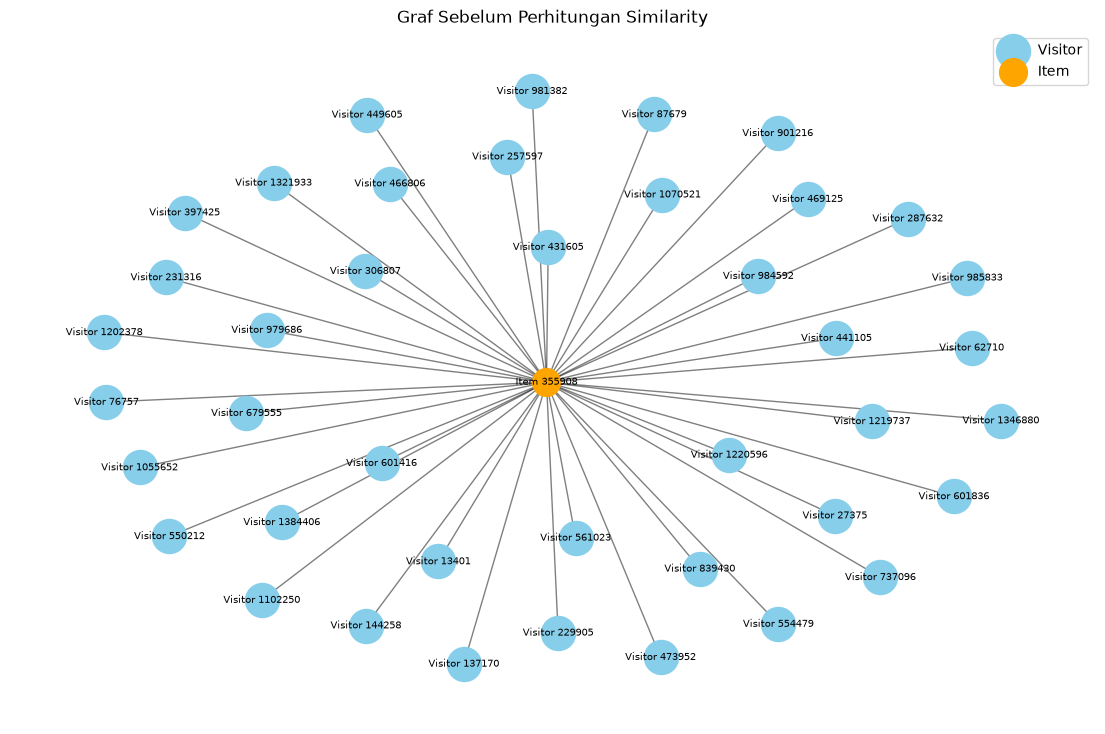

Jumlah record: 50
Jumlah node: 42
Jumlah edge: 41


In [42]:
# Mengambil relasi interaksi asli dari Neo4j
cypher_before = """
MATCH (u:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN u.visitorId AS visitor_id,
       type(r) AS event,
       i.itemId AS item_id
LIMIT 50
"""

with driver.session(database="neo4j") as session:
    records_before = [
        record.data()
        for record in session.run(cypher_before)
    ]

# Membentuk graf
G_before = nx.Graph()

for row in records_before:
    visitor = f"Visitor {row['visitor_id']}"
    item = f"Item {row['item_id']}"

    G_before.add_node(visitor, node_type="Visitor")
    G_before.add_node(item, node_type="Item")
    G_before.add_edge(visitor, item, event=row["event"])

# Visualisasi graf
plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G_before, seed=42)

visitor_nodes = [
    n for n, d in G_before.nodes(data=True)
    if d["node_type"] == "Visitor"
]
item_nodes = [
    n for n, d in G_before.nodes(data=True)
    if d["node_type"] == "Item"
]

nx.draw_networkx_nodes(
    G_before, pos,
    nodelist=visitor_nodes,
    node_color="skyblue",
    node_size=600,
    label="Visitor"
)

nx.draw_networkx_nodes(
    G_before, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=400,
    label="Item"
)

nx.draw_networkx_edges(G_before, pos, alpha=0.5)
nx.draw_networkx_labels(G_before, pos, font_size=7)

plt.title("Graf Sebelum Perhitungan Similarity")
plt.legend()
plt.axis("off")
plt.show()

print("Jumlah record:", len(records_before))
print("Jumlah node:", G_before.number_of_nodes())
print("Jumlah edge:", G_before.number_of_edges())

### Kondisi graf sesudah perhitungan similarity

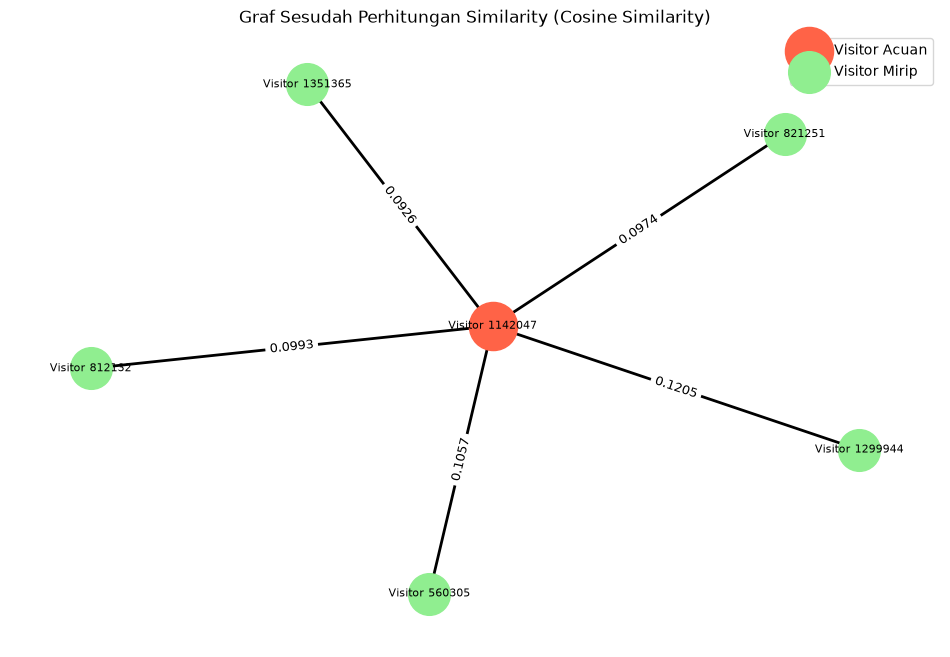

Visitor acuan: 1142047
Jumlah node: 6
Jumlah edge: 5


,visitor_acuan,visitor_mirip,similarity
0,1142047,1299944,0.120528
1,1142047,560305,0.105715
2,1142047,812132,0.099341
3,1142047,821251,0.097434
4,1142047,1351365,0.092626


In [43]:
# Ambil visitor acuan dari hasil perhitungan similarity
anchor_id = int(df_similarity.iloc[0]["visitor_acuan"])

cypher_after = """
MATCH (u:Visitor)-[r:SIMILAR_TO]->(v:Visitor)
WHERE r.period = 'P1'
RETURN u.visitorId AS visitor_acuan,
       v.visitorId AS visitor_mirip,
       r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    records_after = [
        record.data()
        for record in session.run(
            cypher_after, anchor_id=anchor_id
        )
    ]

# Bentuk graf similarity
G_after = nx.Graph()

anchor = f"Visitor {anchor_id}"
G_after.add_node(anchor, node_type="Acuan")

for row in records_after:
    similar_visitor = f"Visitor {row['visitor_mirip']}"

    G_after.add_node(similar_visitor, node_type="Mirip")
    G_after.add_edge(
        anchor,
        similar_visitor,
        similarity=row["similarity"]
    )

# Visualisasi
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G_after, seed=42)

anchor_nodes = [
    node for node, data in G_after.nodes(data=True)
    if data["node_type"] == "Acuan"
]
similar_nodes = [
    node for node, data in G_after.nodes(data=True)
    if data["node_type"] == "Mirip"
]

nx.draw_networkx_nodes(
    G_after, pos, nodelist=anchor_nodes,
    node_color="tomato", node_size=1200, label="Visitor Acuan"
)
nx.draw_networkx_nodes(
    G_after, pos, nodelist=similar_nodes,
    node_color="lightgreen", node_size=900, label="Visitor Mirip"
)
nx.draw_networkx_edges(G_after, pos, width=2)
nx.draw_networkx_labels(G_after, pos, font_size=8)

# Tampilkan nilai similarity pada setiap edge
edge_labels = {
    (u, v): f"{data['similarity']:.4f}"
    for u, v, data in G_after.edges(data=True)
}
nx.draw_networkx_edge_labels(
    G_after, pos, edge_labels=edge_labels, font_size=9
)

plt.title("Graf Sesudah Perhitungan Similarity (Cosine Similarity)")
plt.legend()
plt.axis("off")
plt.show()

print("Visitor acuan:", anchor_id)
print("Jumlah node:", G_after.number_of_nodes())
print("Jumlah edge:", G_after.number_of_edges())

display(pd.DataFrame(records_after))

## **2.2 Analytics**

### Membaca data dan membentuk matriks User–Item 

In [44]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# Membaca dataset periode P1
df_p1 = pd.read_csv("retailrocket_P1.csv")

# Memastikan kolom yang dibutuhkan tersedia
df_p1 = df_p1[["visitorid", "itemid", "event"]].dropna()

# Membentuk indeks unik untuk visitor dan item
visitor_codes, visitor_ids = pd.factorize(df_p1["visitorid"])
item_codes, item_ids = pd.factorize(df_p1["itemid"])

# Membentuk matriks User-Item
VSM = csr_matrix(
    (
        np.ones(len(df_p1), dtype=np.int32),
        (visitor_codes, item_codes)
    ),
    shape=(len(visitor_ids), len(item_ids))
)

# Jika user berinteraksi dengan item yang sama beberapa kali,
# interaksi tersebut dihitung sebagai satu interaksi biner
VSM.data[:] = 1
VSM.eliminate_zeros()

print("Jumlah user:", len(visitor_ids))
print("Jumlah item:", len(item_ids))
print("Ukuran matriks User-Item:", VSM.shape)

Jumlah user: 225151
Jumlah item: 97328
Ukuran matriks User-Item: (225151, 97328)


### Memilih user secara acak dan mencari 5 tetangga terdekat (Nomor 1a)

In [45]:
# Memilih user secara acak dengan seed tetap
rng = np.random.default_rng(42)
random_user_idx = int(rng.integers(0, len(visitor_ids)))

target_user = visitor_ids[random_user_idx]

print("Seed acak:", 42)
print("User terpilih:", target_user)

# Melatih model KNN menggunakan cosine distance
knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=6
)

knn.fit(VSM)

# Ambil 6 kandidat, termasuk user itu sendiri
distances, indices = knn.kneighbors(
    VSM[random_user_idx],
    n_neighbors=min(6, len(visitor_ids))
)

# Hilangkan user itu sendiri, lalu ambil 5 tetangga terdekat
neighbors = []

for idx, distance in zip(indices[0], distances[0]):
    if idx != random_user_idx:
        neighbors.append({
            "visitorid": visitor_ids[idx],
            "cosine_distance": float(distance),
            "similarity": float(1 - distance),
            "matrix_index": int(idx)
        })

    if len(neighbors) == 5:
        break

df_neighbors = pd.DataFrame(neighbors)

print("\nLima tetangga terdekat:")
display(df_neighbors.drop(columns="matrix_index"))

Seed acak: 42
User terpilih: 923147

Lima tetangga terdekat:


,visitorid,cosine_distance,similarity
0,8176,0.00000,1.00000
1,92258,0.00000,1.00000
2,1010308,0.00000,1.00000
3,270660,0.00000,1.00000
4,505744,0.42265,0.57735


### Merekomendasikan 3 item (Nomor 1b)

In [48]:

# Item yang sudah pernah diinteraksikan user target
items_owned = set(VSM[random_user_idx].indices)

# Cari lebih banyak tetangga sebagai cadangan kandidat
n_available = VSM.shape[0]
n_search = min(51, n_available)  # target + maksimal 50 tetangga

distances_all, indices_all = knn.kneighbors(
    VSM[random_user_idx],
    n_neighbors=n_search
)

# Keluarkan user target sendiri
all_neighbors = [
    (idx, distance)
    for idx, distance in zip(indices_all[0], distances_all[0])
    if idx != random_user_idx
]

# Prioritaskan 5 tetangga KNN utama
primary_neighbors = all_neighbors[:5]

def get_item_support(neighbor_list):
    neighbor_indices = [idx for idx, _ in neighbor_list]
    neighbor_matrix = VSM[neighbor_indices]
    return np.asarray(neighbor_matrix.sum(axis=0)).ravel()

# Kandidat dari 5 tetangga pertama
primary_support = get_item_support(primary_neighbors)

candidate_mask = np.ones(VSM.shape[1], dtype=bool)
candidate_mask[list(items_owned)] = False

primary_candidates = np.flatnonzero(
    candidate_mask & (primary_support > 0)
)

# Jika belum ada 3 kandidat, perluas tetangga secara bertahap
selected_neighbors = primary_neighbors.copy()
item_support = primary_support

for neighbor in all_neighbors[5:]:
    if len(primary_candidates) >= 3:
        break

    selected_neighbors.append(neighbor)
    item_support = get_item_support(selected_neighbors)

    primary_candidates = np.flatnonzero(
        candidate_mask & (item_support > 0)
    )

# Urutkan berdasarkan dukungan tertinggi
ranked_indices = primary_candidates[
    np.argsort(item_support[primary_candidates])[::-1]
]

top3_indices = ranked_indices[:3]

df_recommendations = pd.DataFrame({
    "ranking": range(1, len(top3_indices) + 1),
    "itemid": item_ids[top3_indices],
    "jumlah_tetangga_yang_berinteraksi":
        item_support[top3_indices].astype(int)
})

print("User terpilih:", target_user)
print("KNN utama: 5")
print("Jumlah tetangga yang digunakan untuk kandidat:",
      len(selected_neighbors))
display(df_recommendations)


User terpilih: 923147
KNN utama: 5
Jumlah tetangga yang digunakan untuk kandidat: 6


,ranking,itemid,jumlah_tetangga_yang_berinteraksi
0,1,138356,1
1,2,52962,1
2,3,441050,1


Pemilihan user dilakukan secara acak menggunakan seed 42 agar hasil dapat direproduksi. Model KNN dengan cosine distance menentukan lima tetangga terdekat. Karena lima tetangga utama hanya menghasilkan dua kandidat item yang belum pernah diinteraksikan oleh user target, pencarian kandidat diperluas dengan melibatkan satu tetangga berikutnya. Dengan demikian, diperoleh tiga rekomendasi, yaitu item 138356, 52962, dan 441050, yang masing-masing didukung oleh satu tetangga.

### Menyiapkan data P2

In [49]:
df_p2 = pd.read_csv("retailrocket_P2.csv")

# Interaksi aktual user target pada periode P2
actual_items = set(
    df_p2.loc[
        df_p2["visitorid"] == target_user,
        "itemid"
    ].dropna().astype(int)
)

print("User target:", target_user)
print("Jumlah item yang berinteraksi pada P2:", len(actual_items))

User target: 923147
Jumlah item yang berinteraksi pada P2: 0


### Membuat lima rekomendasi teratas

In [50]:
# Urutkan kandidat berdasarkan jumlah tetangga yang berinteraksi
ranked_indices = primary_candidates[
    np.argsort(item_support[primary_candidates])[::-1]
]

# Ambil maksimal 5 item rekomendasi
top5_indices = ranked_indices[:5]

df_top5 = pd.DataFrame({
    "ranking": range(1, len(top5_indices) + 1),
    "itemid": item_ids[top5_indices].astype(int),
    "support": item_support[top5_indices].astype(int)
})

# Tandai item yang relevan berdasarkan interaksi aktual di P2
df_top5["relevan"] = df_top5["itemid"].isin(actual_items).astype(int)

display(df_top5)

,ranking,itemid,support,relevan
0,1,138356,1,0
1,2,52962,1,0
2,3,441050,1,0
3,4,51650,1,0


### Hitung Hit@5 dan NDCG@5 (Nomor 2a dan 2b)

In [51]:
# Hit@5: apakah ada minimal satu item relevan di top-5?
hit_at_5 = int(df_top5["relevan"].sum() > 0)

# DCG@5: item relevan yang posisinya lebih tinggi mendapat bobot lebih besar
relevance = df_top5["relevan"].to_numpy()
positions = np.arange(1, len(relevance) + 1)

dcg_at_5 = np.sum(
    relevance / np.log2(positions + 1)
)

# IDCG@5: nilai DCG ideal berdasarkan jumlah item relevan
ideal_relevance = np.sort(relevance)[::-1]

idcg_at_5 = np.sum(
    ideal_relevance / np.log2(positions + 1)
)

# Hindari pembagian dengan nol
ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

print(f"Hit@5  : {hit_at_5:.4f}")
print(f"NDCG@5 : {ndcg_at_5:.4f}")

Hit@5  : 0.0000
NDCG@5 : 0.0000
